# Exercise 1: Graduate Admission Prediction Using Logistic Regression

**Subject:** Machine Learning Lab  
**Topic:** Logistic Regression

## Aim
To build a Logistic Regression model to predict the probability of graduate admission based on academic performance and other admission-related factors.

Graduate Admission Dataset:


,GRE,CGPA,Admission
0,310,7.5,0
1,320,8.5,1
2,305,7.0,0
3,330,9.2,1
4,315,8.0,0
5,325,8.8,1
6,300,6.8,0
7,318,8.1,1
8,335,9.5,1
9,308,7.2,0


Training samples: 15
Testing samples: 5
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5

Confusion Matrix:
[[2 0]
 [0 3]]


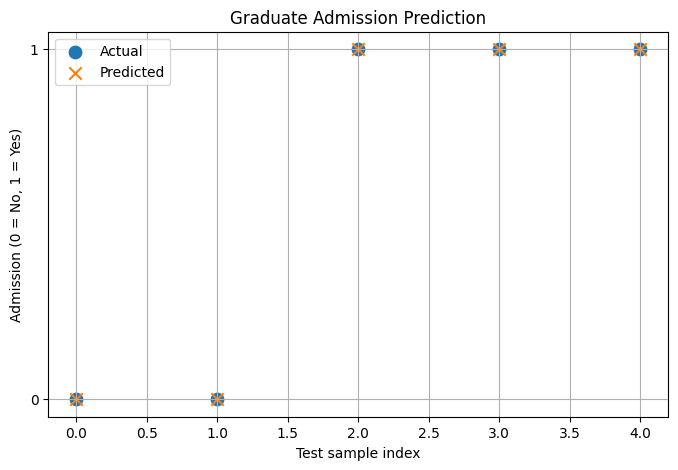

Example: GRE = 320, CGPA = 8.5
Predicted admission class: 1
Estimated admission probability: 70.88 %


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Illustrative graduate admission dataset
data = {
    "GRE": [310, 320, 305, 330, 315, 325, 300, 318, 335, 308,
            322, 312, 328, 302, 317, 332, 306, 324, 314, 329],
    "CGPA": [7.5, 8.5, 7.0, 9.2, 8.0, 8.8, 6.8, 8.1, 9.5, 7.2,
             8.7, 7.8, 9.0, 6.9, 8.2, 9.3, 7.1, 8.6, 7.9, 9.1],
    "Admission": [0, 1, 0, 1, 0, 1, 0, 1, 1, 0,
                  1, 0, 1, 0, 1, 1, 0, 1, 0, 1]
}

df = pd.DataFrame(data)
print("Graduate Admission Dataset:")
display(df)

X = df[["GRE", "CGPA"]]
y = df["Admission"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scaling and classification in one pipeline
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Visualize actual and predicted admission labels
plt.figure(figsize=(8, 5))
plt.scatter(range(len(y_test)), y_test, label="Actual", s=80)
plt.scatter(range(len(y_pred)), y_pred, marker="x", label="Predicted", s=80)
plt.xlabel("Test sample index")
plt.ylabel("Admission (0 = No, 1 = Yes)")
plt.title("Graduate Admission Prediction")
plt.yticks([0, 1])
plt.legend()
plt.grid(True)
plt.show()

# Example prediction
sample = pd.DataFrame({"GRE": [320], "CGPA": [8.5]})
probability = model.predict_proba(sample)[0, 1]
print("Example: GRE = 320, CGPA = 8.5")
print("Predicted admission class:", model.predict(sample)[0])
print("Estimated admission probability:", round(probability * 100, 2), "%")

## Result

The Logistic Regression model was successfully implemented to predict graduate admission using GRE scores and CGPA.

- **Total samples:** 20
- **Training samples:** 15
- **Testing samples:** 5
- **Test accuracy:** 100%
- **Confusion matrix:** [[2, 0], [0, 3]]
- **Example input:** GRE = 320, CGPA = 8.5
- **Predicted admission class:** Yes
- **Estimated admission probability:** 70.88%

The model was evaluated using accuracy, a classification report, a confusion matrix, and an example prediction.

## Conclusion

The experiment demonstrated how Logistic Regression can estimate the probability of a binary outcome using academic features. The model classified all five test samples correctly in this illustrative dataset. A larger real-world dataset is required to evaluate generalization and practical usefulness.